In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/ravikumarrao50/imdb-dataset-of-50k-movie-reviews/IMDB Dataset.csv


In [4]:

import pandas as pd
import numpy as np
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

print("All libraries imported successfully! ✅")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)


All libraries imported successfully! ✅
Pandas: 2.3.3
NumPy: 2.1.3
Scikit-learn: 1.6.1


In [6]:

# CELL 1: Import libraries and load your dataset

import os
import glob
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from io import BytesIO

# Search for the CSV in Kaggle input folders
csv_files = glob.glob("/kaggle/input/**/*.csv", recursive=True)
zip_files = glob.glob("/kaggle/input/**/*.zip", recursive=True)

if csv_files:
    csv_path = next(
        (f for f in csv_files if "imdb" in os.path.basename(f).lower()),
        csv_files[0]
    )
    df = pd.read_csv(csv_path)
    print("Dataset loaded from:", csv_path)

elif zip_files:
    zip_path = zip_files[0]
    with zipfile.ZipFile(zip_path, "r") as z:
        csv_name = next(
            (f for f in z.namelist()
             if f.lower().endswith(".csv") and "imdb" in f.lower()),
            next(f for f in z.namelist() if f.lower().endswith(".csv"))
        )
        with z.open(csv_name) as f:
            df = pd.read_csv(f)
    print("Dataset loaded from ZIP:", zip_path)

else:
    raise FileNotFoundError(
        "Dataset not found. Click Add Input in Kaggle "
        "and attach IMDb Dataset of 50K Movie Reviews."
    )

print("\nDataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
display(df.head())


Dataset loaded from: /kaggle/input/datasets/ravikumarrao50/imdb-dataset-of-50k-movie-reviews/IMDB Dataset.csv

Dataset shape: (50000, 2)

Columns: ['review', 'sentiment']


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [7]:

# CELL 2: Clean and prepare the dataset

import re
from html import unescape

# Check required columns
required_columns = {"review", "sentiment"}

if not required_columns.issubset(df.columns):
    raise ValueError(
        f"Expected columns {required_columns}, "
        f"but found {df.columns.tolist()}"
    )

df = df[["review", "sentiment"]].dropna().copy()

df["sentiment"] = (
    df["sentiment"].astype(str).str.strip().str.lower()
)

df = df[df["sentiment"].isin(["positive", "negative"])]

df = df.drop_duplicates(subset=["review"]).reset_index(drop=True)

def clean_text(text):
    text = unescape(str(text))
    text = re.sub(r"<br\s*/?>", " ", text, flags=re.I)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[^a-zA-Z\s']", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip().lower()

df["clean_review"] = df["review"].apply(clean_text)

# Positive = 1, Negative = 0
df["label"] = df["sentiment"].map({
    "negative": 0,
    "positive": 1
})

print("Cleaned dataset shape:", df.shape)
print("\nSentiment counts:")
print(df["sentiment"].value_counts())

display(df[["review", "clean_review", "sentiment"]].head())


Cleaned dataset shape: (49582, 4)

Sentiment counts:
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


,review,clean_review,sentiment
0,One of the other reviewers has mentioned that ...,one of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,a wonderful little production the filming tech...,positive
2,I thought this was a wonderful way to spend ti...,i thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",petter mattei's love in the time of money is a...,positive


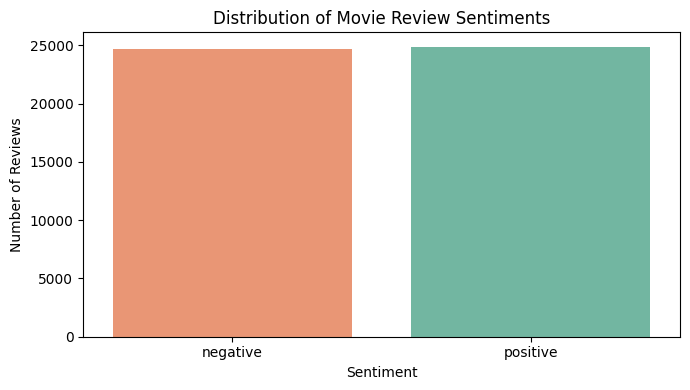

In [8]:

# CELL 3: Sentiment distribution

plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x="sentiment",
    hue="sentiment",
    order=["negative", "positive"],
    palette="Set2",
    legend=False
)

plt.title("Distribution of Movie Review Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


In [9]:

# CELL 4: Train-test split and TF-IDF

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["clean_review"],
    df["label"],
    test_size=0.20,
    random_state=42,
    stratify=df["label"]
)

vectorizer = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of TF-IDF features:", X_train.shape[1])


Training samples: 39665
Testing samples: 9917
Number of TF-IDF features: 30000


In [10]:

# CELL 5: Train Logistic Regression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Model training completed successfully!")


Model training completed successfully!


In [11]:

# CELL 6: Model evaluation

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Negative", "Positive"]
))



Test Accuracy: 90.72%

Classification Report:

              precision    recall  f1-score   support

    Negative       0.92      0.89      0.91      4940
    Positive       0.90      0.92      0.91      4977

    accuracy                           0.91      9917
   macro avg       0.91      0.91      0.91      9917
weighted avg       0.91      0.91      0.91      9917



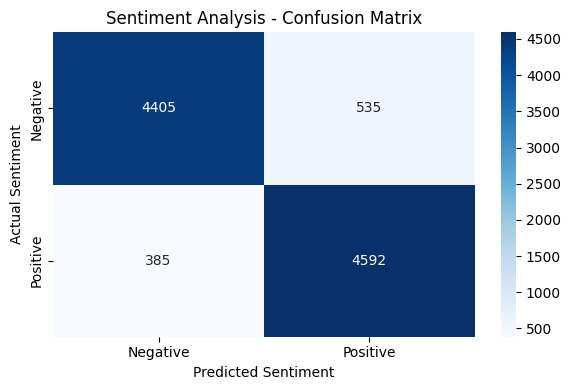

In [12]:

# CELL 7: Confusion matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("Sentiment Analysis - Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.tight_layout()
plt.show()


In [13]:

# CELL 8: Predict sentiment for any new review

def predict_sentiment(review):
    cleaned_review = clean_text(review)
    features = vectorizer.transform([cleaned_review])

    prediction = model.predict(features)[0]
    probabilities = model.predict_proba(features)[0]

    sentiment = "Positive 😊" if prediction == 1 else "Negative 😞"
    confidence = probabilities[int(prediction)] * 100

    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print(f"Model Confidence: {confidence:.2f}%")

predict_sentiment(
    "This movie was fantastic. The acting was brilliant!"
)

print("\n" + "-" * 50 + "\n")

predict_sentiment(
    "This movie was boring and a complete waste of time."
)


Review: This movie was fantastic. The acting was brilliant!
Predicted Sentiment: Positive 😊
Model Confidence: 81.21%

--------------------------------------------------

Review: This movie was boring and a complete waste of time.
Predicted Sentiment: Negative 😞
Model Confidence: 99.61%


In [14]:

# CELL 9: Save model and TF-IDF vectorizer

output_dir = "/kaggle/working"

joblib.dump(
    model,
    os.path.join(output_dir, "sentiment_model.pkl")
)

joblib.dump(
    vectorizer,
    os.path.join(output_dir, "tfidf_vectorizer.pkl")
)

print("Saved files:")
print("/kaggle/working/sentiment_model.pkl")
print("/kaggle/working/tfidf_vectorizer.pkl")


Saved files:
/kaggle/working/sentiment_model.pkl
/kaggle/working/tfidf_vectorizer.pkl
